# Home Credit : scoring du risque de défaut de crédit
## Notebook 01 : exploration de la table principale

**Contexte.** Home Credit est un organisme de crédit à la consommation qui prête en priorité à des personnes peu ou pas bancarisées, sans historique de crédit exploitable. Pour accorder un prêt sans s'exposer à trop de défauts, il doit estimer, au moment de la demande, la probabilité que le client rencontre des difficultés de remboursement.

**Cible.** `TARGET = 1` si le client a eu un retard de paiement de plus de *X* jours sur au moins une des *Y* premières échéances de son prêt, `0` sinon.

**Objectif de ce notebook.** Comprendre la table principale `application_train` avant toute modélisation :
1. fixer une fois pour toutes le découpage apprentissage / test ;
2. étudier la cible et ses conséquences sur les métriques ;
3. organiser les 122 variables en familles ;
4. diagnostiquer les valeurs manquantes et les anomalies ;
5. mesurer le pouvoir discriminant de chaque variable (AUC univariée, Information Value) ;
6. repérer les redondances et les variables dérivées prometteuses ;
7. identifier les variables sensibles du point de vue de l'équité ;
8. en déduire les règles de nettoyage du notebook suivant.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

GRAINE = 42
DOSSIER_BRUTES = Path("../data/brutes")
DOSSIER_TRAITEES = Path("../data/traitees")
DOSSIER_TRAITEES.mkdir(parents=True, exist_ok=True)

# 1. Chargement

In [2]:
donnees = pd.read_csv(DOSSIER_BRUTES / "application_train.csv")
dictionnaire = pd.read_csv(DOSSIER_BRUTES / "HomeCredit_columns_description.csv", encoding="latin-1")
dictionnaire = dictionnaire[dictionnaire["Table"] == "application_{train|test}.csv"].set_index("Row")["Description"]

print(f"Dimensions : {donnees.shape[0]:,} demandes x {donnees.shape[1]} colonnes".replace(",", " "))
print(f"Mémoire : {donnees.memory_usage(deep=True).sum() / 1e6:.0f} Mo")
print(f"Identifiant unique : {donnees['SK_ID_CURR'].is_unique}")
print(donnees.dtypes.astype(str).value_counts())

Dimensions : 307 511 demandes x 122 colonnes
Mémoire : 341 Mo
Identifiant unique : True
float64    65
int64      41
str        16
Name: count, dtype: int64


In [3]:
def decrire(variable):
    """Renvoie la description officielle d'une variable."""
    return dictionnaire.get(variable, "(pas de description)")


for v in ["TARGET", "EXT_SOURCE_1", "DAYS_EMPLOYED", "AMT_GOODS_PRICE", "REGION_RATING_CLIENT"]:
    print(f"{v:<22} {decrire(v)}")

TARGET                 Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)
EXT_SOURCE_1           Normalized score from external data source
DAYS_EMPLOYED          How many days before the application the person started current employment
AMT_GOODS_PRICE        For consumer loans it is the price of the goods for which the loan is given
REGION_RATING_CLIENT   Our rating of the region where client lives (1,2,3)


# 2. Découpage apprentissage / test, fixé dès maintenant

Toutes les décisions prises pendant l'exploration (seuils, regroupements, variables retenues) doivent l'être **sans regarder l'échantillon de test**, sinon l'évaluation finale serait optimiste. On isole donc 20 % des demandes dès le départ, en conservant la proportion de défauts (découpage stratifié), et on enregistre la liste des identifiants. Tous les notebooks suivants réutiliseront exactement ce découpage.

Le fichier `application_test.csv` fourni par Kaggle ne contient pas la cible : il ne peut pas servir à mesurer la performance.

In [4]:
ids_app, ids_test = train_test_split(donnees["SK_ID_CURR"], test_size=0.20,
                                     stratify=donnees["TARGET"], random_state=GRAINE)
decoupage = pd.DataFrame({"SK_ID_CURR": donnees["SK_ID_CURR"]})
decoupage["echantillon"] = np.where(decoupage["SK_ID_CURR"].isin(ids_test), "test", "apprentissage")
decoupage.to_csv(DOSSIER_TRAITEES / "decoupage.csv", index=False)

df = donnees[donnees["SK_ID_CURR"].isin(ids_app)].reset_index(drop=True)
print(decoupage.merge(donnees[["SK_ID_CURR", "TARGET"]]).groupby("echantillon")["TARGET"].agg(["size", "mean"]).round(4))
print("\nLa suite de l'exploration porte uniquement sur l'échantillon d'apprentissage.")

                 size    mean
echantillon                  
apprentissage  246008  0.0807
test            61503  0.0807

La suite de l'exploration porte uniquement sur l'échantillon d'apprentissage.


# 3. La cible

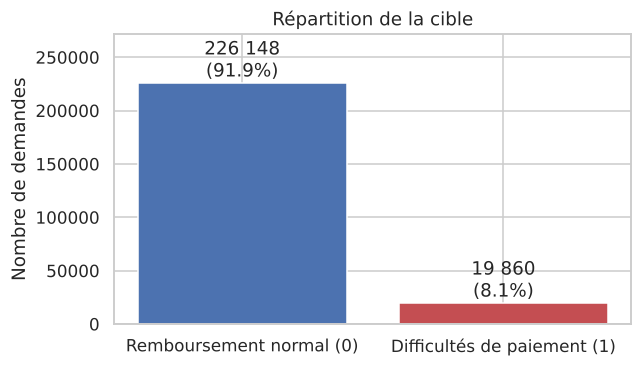

Taux de défaut : 8.07%
Exactitude d'un modèle qui prédit toujours « pas de défaut » : 91.93%


In [5]:
taux_defaut = df["TARGET"].mean()
comptes = df["TARGET"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Remboursement normal (0)", "Difficultés de paiement (1)"], comptes.values, color=["#4C72B0", "#C44E52"])
for i, n in enumerate(comptes.values):
    ax.text(i, n, f"{n:,}\n({n / len(df):.1%})".replace(",", " "), ha="center", va="bottom")
ax.set(ylabel="Nombre de demandes", title="Répartition de la cible", ylim=(0, comptes.max() * 1.2))
plt.tight_layout()
plt.show()

print(f"Taux de défaut : {taux_defaut:.2%}")
print(f"Exactitude d'un modèle qui prédit toujours « pas de défaut » : {1 - taux_defaut:.2%}")

**Lecture.** 8,07 % des demandes ont connu des difficultés de paiement, soit un défaut pour onze remboursements normaux. Ce déséquilibre a trois conséquences pour la suite :

- **L'exactitude est inutilisable.** Un modèle qui accepte tout le monde atteint 91,9 % d'exactitude sans rien prédire.
- **Les métriques retenues** seront l'AUC ROC (et son équivalent bancaire, le coefficient de Gini = 2 × AUC − 1), l'AUC précision-rappel, qui se concentre sur la classe rare, et le score de Brier pour la qualité des probabilités.
- **Le seuil d'octroi** ne sera pas fixé à 0,5 par défaut. Il sera choisi à partir du coût d'un défaut comparé au manque à gagner d'un bon client refusé. La validation croisée sera stratifiée pour conserver 8 % de défauts dans chaque pli.

# 4. Les familles de variables

In [6]:
def famille(v):
    if v in ("SK_ID_CURR", "TARGET"):
        return "Identifiant et cible"
    if v.startswith("EXT_SOURCE"):
        return "Scores externes"
    if v.startswith("FLAG_DOCUMENT"):
        return "Documents fournis"
    if v.startswith("AMT_REQ_CREDIT_BUREAU"):
        return "Consultations du bureau de crédit"
    if "SOCIAL_CIRCLE" in v:
        return "Défauts dans l'entourage"
    if v.endswith(("_AVG", "_MODE", "_MEDI")):
        return "Caractéristiques de l'immeuble"
    if v.startswith(("REGION_", "REG_", "LIVE_")):
        return "Région et adresse"
    if v in ("FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE", "FLAG_CONT_MOBILE", "FLAG_PHONE", "FLAG_EMAIL"):
        return "Coordonnées fournies"
    if v in ("NAME_CONTRACT_TYPE", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "NAME_TYPE_SUITE",
             "WEEKDAY_APPR_PROCESS_START", "HOUR_APPR_PROCESS_START"):
        return "Crédit demandé"
    if v in ("AMT_INCOME_TOTAL", "NAME_INCOME_TYPE", "DAYS_EMPLOYED", "OCCUPATION_TYPE", "ORGANIZATION_TYPE"):
        return "Revenus et emploi"
    if v in ("FLAG_OWN_CAR", "FLAG_OWN_REALTY", "OWN_CAR_AGE", "NAME_HOUSING_TYPE"):
        return "Patrimoine et logement"
    if v in ("DAYS_REGISTRATION", "DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE"):
        return "Dates administratives"
    return "Profil sociodémographique"


familles = pd.Series({v: famille(v) for v in df.columns}, name="famille")
resume_familles = (pd.DataFrame({"famille": familles, "manquants": df.isna().mean()})
                   .groupby("famille")
                   .agg(nb_variables=("manquants", "size"), taux_manquants_moyen=("manquants", "mean"))
                   .sort_values("nb_variables", ascending=False))
resume_familles["taux_manquants_moyen"] = (resume_familles["taux_manquants_moyen"] * 100).round(1)
resume_familles

,nb_variables,taux_manquants_moyen
famille,,
Caractéristiques de l'immeuble,47,57.8
Documents fournis,20,0.0
Région et adresse,9,0.0
Crédit demandé,7,0.1
Consultations du bureau de crédit,6,13.5
Profil sociodémographique,6,0.0
Coordonnées fournies,6,0.0
Revenus et emploi,5,6.3
Défauts dans l'entourage,4,0.3


In [7]:
for f in ["Profil sociodémographique", "Revenus et emploi", "Crédit demandé", "Scores externes"]:
    print(f"\n{f} :")
    for v in familles[familles == f].index:
        print(f"  {v:<28} {decrire(v)[:95]}")


Profil sociodémographique :


  CODE_GENDER                  Gender of the client
  CNT_CHILDREN                 Number of children the client has
  NAME_EDUCATION_TYPE          Level of highest education the client achieved
  NAME_FAMILY_STATUS           Family status of the client
  DAYS_BIRTH                   Client's age in days at the time of application
  CNT_FAM_MEMBERS              How many family members does client have

Revenus et emploi :
  AMT_INCOME_TOTAL             Income of the client
  NAME_INCOME_TYPE             Clients income type (businessman, working, maternity leave,)
  DAYS_EMPLOYED                How many days before the application the person started current employment
  OCCUPATION_TYPE              What kind of occupation does the client have
  ORGANIZATION_TYPE            Type of organization where client works

Crédit demandé :
  NAME_CONTRACT_TYPE           Identification if loan is cash or revolving
  AMT_CREDIT                   Credit amount of the loan
  AMT_ANNUITY             

**Lecture.** Les 120 variables explicatives se répartissent en 13 familles très inégales. Les **caractéristiques de l'immeuble** du client représentent à elles seules 47 variables, soit près de 40 % des colonnes, avec 58 % de valeurs manquantes en moyenne. Les **documents fournis** comptent 20 indicatrices. À l'inverse, les familles qu'un analyste crédit regarderait en premier (revenus, crédit demandé, scores externes) ne comptent qu'une quinzaine de variables. Le nombre de colonnes ne dit donc rien de l'information utile : il faudra mesurer le pouvoir discriminant de chaque famille (section 8).

# 5. Valeurs manquantes

## 5.1 Ampleur

67 variables sur 122 ont des valeurs manquantes.
  plus de 40 % : 49   plus de 60 % : 17


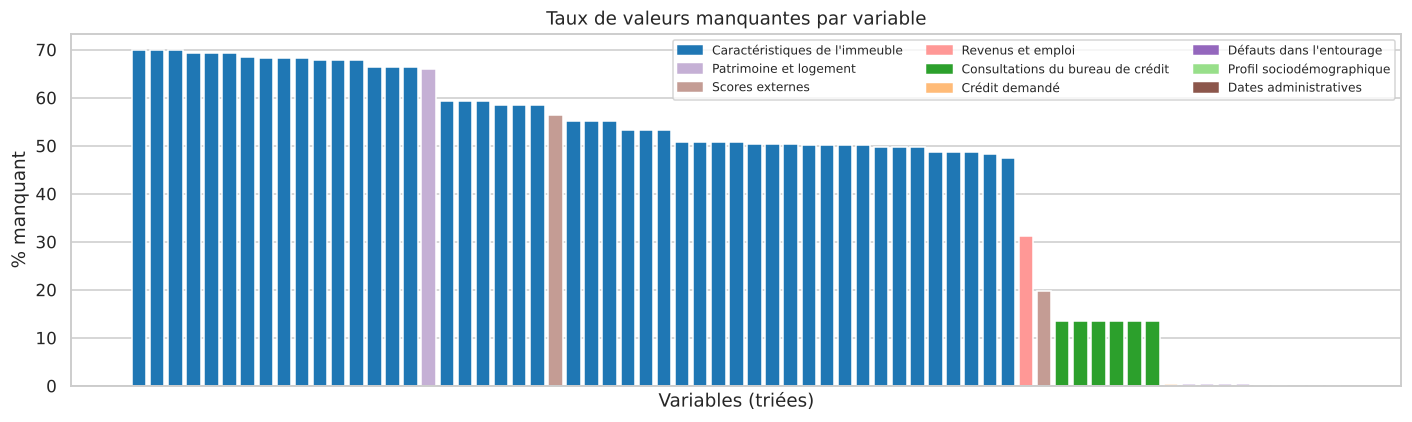

,famille,% manquant
COMMONAREA_AVG,Caractéristiques de l'immeuble,69.8
COMMONAREA_MODE,Caractéristiques de l'immeuble,69.8
COMMONAREA_MEDI,Caractéristiques de l'immeuble,69.8
NONLIVINGAPARTMENTS_MEDI,Caractéristiques de l'immeuble,69.4
NONLIVINGAPARTMENTS_MODE,Caractéristiques de l'immeuble,69.4
NONLIVINGAPARTMENTS_AVG,Caractéristiques de l'immeuble,69.4
FONDKAPREMONT_MODE,Caractéristiques de l'immeuble,68.4
LIVINGAPARTMENTS_AVG,Caractéristiques de l'immeuble,68.3
LIVINGAPARTMENTS_MEDI,Caractéristiques de l'immeuble,68.3
LIVINGAPARTMENTS_MODE,Caractéristiques de l'immeuble,68.3


In [8]:
manquants = df.isna().mean().sort_values(ascending=False)
manquants = manquants[manquants > 0]
print(f"{len(manquants)} variables sur {df.shape[1]} ont des valeurs manquantes.")
print(f"  plus de 40 % : {(manquants > 0.4).sum()}   plus de 60 % : {(manquants > 0.6).sum()}")

fig, ax = plt.subplots(figsize=(13, 4))
couleurs = [plt.cm.tab20(list(resume_familles.index).index(familles[v]) % 20) for v in manquants.index]
ax.bar(range(len(manquants)), manquants.values * 100, color=couleurs)
ax.set(xlabel="Variables (triées)", ylabel="% manquant", title="Taux de valeurs manquantes par variable", xticks=[])
legende = {familles[v]: c for v, c in zip(manquants.index, couleurs)}
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in legende.values()], labels=list(legende.keys()),
          fontsize=8, ncol=3, loc="upper right")
plt.tight_layout()
plt.show()

pd.DataFrame({"famille": familles[manquants.index], "% manquant": (manquants * 100).round(1)}).head(15)

## 5.2 Les valeurs manquent-elles au hasard ?

Si une valeur manque complètement au hasard (MCAR), le taux de défaut doit être le même que la valeur soit renseignée ou non. On compare les deux groupes pour les principales variables incomplètes.

In [9]:
lignes = []
for v in ["EXT_SOURCE_1", "EXT_SOURCE_3", "EXT_SOURCE_2", "OWN_CAR_AGE", "OCCUPATION_TYPE",
          "APARTMENTS_AVG", "AMT_REQ_CREDIT_BUREAU_YEAR", "AMT_GOODS_PRICE"]:
    manque = df[v].isna()
    lignes.append({"variable": v, "% manquant": manque.mean() * 100,
                   "défaut si manquant (%)": df.loc[manque, "TARGET"].mean() * 100,
                   "défaut si renseigné (%)": df.loc[~manque, "TARGET"].mean() * 100})
test_mcar = pd.DataFrame(lignes)
test_mcar["écart (points)"] = test_mcar["défaut si manquant (%)"] - test_mcar["défaut si renseigné (%)"]
test_mcar.round(2)

,variable,% manquant,défaut si manquant (%),défaut si renseigné (%),écart (points)
0,EXT_SOURCE_1,56.34,8.52,7.49,1.04
1,EXT_SOURCE_3,19.84,9.28,7.77,1.50
2,EXT_SOURCE_2,0.22,7.72,8.07,-0.35
3,OWN_CAR_AGE,66.02,8.48,7.27,1.21
4,OCCUPATION_TYPE,31.28,6.49,8.79,-2.30
5,APARTMENTS_AVG,50.70,9.14,6.98,2.16
6,AMT_REQ_CREDIT_BUREAU_YEAR,13.51,10.34,7.72,2.62
7,AMT_GOODS_PRICE,0.09,7.69,8.07,-0.38


**Lecture.** Les valeurs ne manquent pas au hasard : le taux de défaut change selon que la variable est renseignée ou non. On distingue trois situations :

1. **Absence structurelle.** `OWN_CAR_AGE` manque exactement pour les clients sans voiture (vérifié avec `FLAG_OWN_CAR`). `OCCUPATION_TYPE` manque pour la quasi-totalité des retraités, qui n'ont plus de profession. Ici, la valeur n'existe pas : imputer un âge de voiture à un client sans voiture n'aurait aucun sens. On codera « sans objet ».
2. **Absence informative.** Quand les informations sur l'immeuble manquent, le taux de défaut passe de 7,0 % à 9,1 %. Quand le nombre de consultations du bureau de crédit manque, il passe de 7,7 % à 10,3 %. Le fait même de ne pas avoir l'information est un signal de risque, cohérent avec un mécanisme MAR, voire MNAR.
3. **Absence quasi aléatoire.** `EXT_SOURCE_2` et `AMT_GOODS_PRICE` manquent dans moins de 0,3 % des cas, sans écart notable.

**Décisions :** aucune ligne supprimée ; une **indicatrice de valeur manquante** pour les variables où l'absence est informative ; une imputation simple (médiane ou modalité) **apprise sur l'échantillon d'apprentissage** dans le pipeline ; un codage « sans objet » pour les absences structurelles.

# 6. Anomalies et valeurs aberrantes

## 6.1 Les durées en jours

Les variables `DAYS_*` sont exprimées en jours **avant la demande**, donc négatives. On les convertit en années pour les lire.

In [10]:
jours = [c for c in df.columns if c.startswith("DAYS_")]
(df[jours].describe().T[["min", "50%", "max"]] / -365.25).round(1).rename(columns={"min": "max (ans)", "50%": "médiane (ans)", "max": "min (ans)"})

,max (ans),médiane (ans),min (ans)
DAYS_BIRTH,69.1,43.1,20.5
DAYS_EMPLOYED,49.0,3.3,-1000.0
DAYS_REGISTRATION,67.5,12.3,-0.0
DAYS_ID_PUBLISH,19.7,8.9,-0.0
DAYS_LAST_PHONE_CHANGE,11.8,2.1,-0.0


`DAYS_EMPLOYED` atteint une valeur positive de 365 243 jours, soit un **millier d'années d'ancienneté**. C'est un code, pas une durée.

In [11]:
code_anomalie = 365243
anomalie_emploi = df["DAYS_EMPLOYED"] == code_anomalie
print(f"Demandes concernées : {anomalie_emploi.sum():,} ({anomalie_emploi.mean():.1%})".replace(",", " "))
print("\nType de revenu de ces clients :")
print(df.loc[anomalie_emploi, "NAME_INCOME_TYPE"].value_counts())
print("\nType d'employeur de ces clients :")
print(df.loc[anomalie_emploi, "ORGANIZATION_TYPE"].value_counts())
print(f"\nTaux de défaut avec le code : {df.loc[anomalie_emploi, 'TARGET'].mean():.2%}")
print(f"Taux de défaut sans le code : {df.loc[~anomalie_emploi, 'TARGET'].mean():.2%}")

Demandes concernées : 44 143 (17.9%)

Type de revenu de ces clients :
NAME_INCOME_TYPE
Pensioner     44126
Unemployed       17
Name: count, dtype: int64

Type d'employeur de ces clients :
ORGANIZATION_TYPE
XNA    44143
Name: count, dtype: int64

Taux de défaut avec le code : 5.37%
Taux de défaut sans le code : 8.66%


**Lecture.** Le code 365 243 concerne 17,9 % des demandes et correspond exactement aux **retraités (et à 17 chômeurs)**, dont l'employeur est lui aussi codé `XNA`. Ce n'est pas une erreur aléatoire, c'est la façon dont la base code l'absence d'emploi. Ce groupe est d'ailleurs **moins risqué** que la moyenne (5,4 % de défaut contre 8,7 %).

**Décision :** remplacer le code par une valeur manquante et créer une indicatrice `SANS_EMPLOI`. Laisser 365 243 tel quel ferait de ces clients des employés à 1 000 ans d'ancienneté, ce qui fausserait tout modèle linéaire et toute standardisation.

## 6.2 Modalités inconnues

In [12]:
for v in ["CODE_GENDER", "NAME_FAMILY_STATUS", "ORGANIZATION_TYPE"]:
    inconnues = df[v].isin(["XNA", "Unknown"])
    print(f"{v:<20} modalité inconnue : {inconnues.sum():>6} demandes")

CODE_GENDER          modalité inconnue :      2 demandes
NAME_FAMILY_STATUS   modalité inconnue :      2 demandes
ORGANIZATION_TYPE    modalité inconnue :  44143 demandes


`CODE_GENDER = XNA` et `NAME_FAMILY_STATUS = Unknown` ne concernent que quelques demandes : ce sont des valeurs manquantes déguisées. `ORGANIZATION_TYPE = XNA` correspond exactement aux retraités et chômeurs de la section précédente.

## 6.3 Montants extrêmes

In [13]:
montants = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
df[montants].describe(percentiles=[0.01, 0.5, 0.99, 0.999]).T.round(0)

,count,mean,std,min,1%,50%,99%,99.9%,max
AMT_INCOME_TOTAL,246008.0,168853.0,258961.0,25650.0,45000.0,147600.0,472500.0,900000.0,117000000.0
AMT_CREDIT,246008.0,599338.0,402726.0,45000.0,76410.0,514778.0,1862802.0,2517300.0,4050000.0
AMT_ANNUITY,245998.0,27108.0,14521.0,1616.0,6188.0,24903.0,70034.0,111002.0,258026.0
AMT_GOODS_PRICE,245787.0,538653.0,369595.0,40500.0,67500.0,450000.0,1800000.0,2250000.0,4050000.0


In [14]:
print("Les cinq revenus les plus élevés :")
print(df.nlargest(5, "AMT_INCOME_TOTAL")[["AMT_INCOME_TOTAL", "AMT_CREDIT", "NAME_INCOME_TYPE", "OCCUPATION_TYPE", "TARGET"]])

Les cinq revenus les plus élevés :
        AMT_INCOME_TOTAL  AMT_CREDIT      NAME_INCOME_TYPE OCCUPATION_TYPE  TARGET
10196        117000000.0    562491.0               Working        Laborers       1
162803        18000090.0    675000.0  Commercial associate             NaN       0
62149          9000000.0   1431531.0               Working        Managers       0
104746         6750000.0    790830.0               Working        Laborers       0
82265          4500000.0   2250000.0               Working        Managers       0


In [15]:
print("Valeurs maximales de quelques compteurs :")
print(df[["CNT_CHILDREN", "CNT_FAM_MEMBERS", "OBS_30_CNT_SOCIAL_CIRCLE", "DEF_30_CNT_SOCIAL_CIRCLE",
          "AMT_REQ_CREDIT_BUREAU_QRT", "OWN_CAR_AGE"]].agg(["median", "max"]).T)

Valeurs maximales de quelques compteurs :
                           median    max
CNT_CHILDREN                  0.0   19.0
CNT_FAM_MEMBERS               2.0   20.0
OBS_30_CNT_SOCIAL_CIRCLE      0.0  348.0
DEF_30_CNT_SOCIAL_CIRCLE      0.0   34.0
AMT_REQ_CREDIT_BUREAU_QRT     0.0   19.0
OWN_CAR_AGE                   9.0   91.0


**Lecture.**
- **Le revenu de 117 millions** est une erreur de saisie évidente : ce client est ouvrier (`Laborers`), emprunte 562 000 et a fait défaut. Le revenu suivant est six fois plus faible. Les revenus au-delà du 99,9ᵉ centile (900 000) sont rares et rendent l'échelle illisible : on les **écrêtera** à une borne apprise sur l'apprentissage, plutôt que de supprimer les lignes.
- **Les montants du crédit** sont réguliers (de 45 000 à 4 millions), sans anomalie.
- **Les compteurs** contiennent quelques valeurs extrêmes mais plausibles : 19 enfants, une voiture de 91 ans, 348 personnes observées dans l'entourage. Les modèles à base d'arbres y sont insensibles ; pour la régression logistique, on écrêtera aussi.

# 7. Relations avec le défaut

## 7.1 Âge et ancienneté

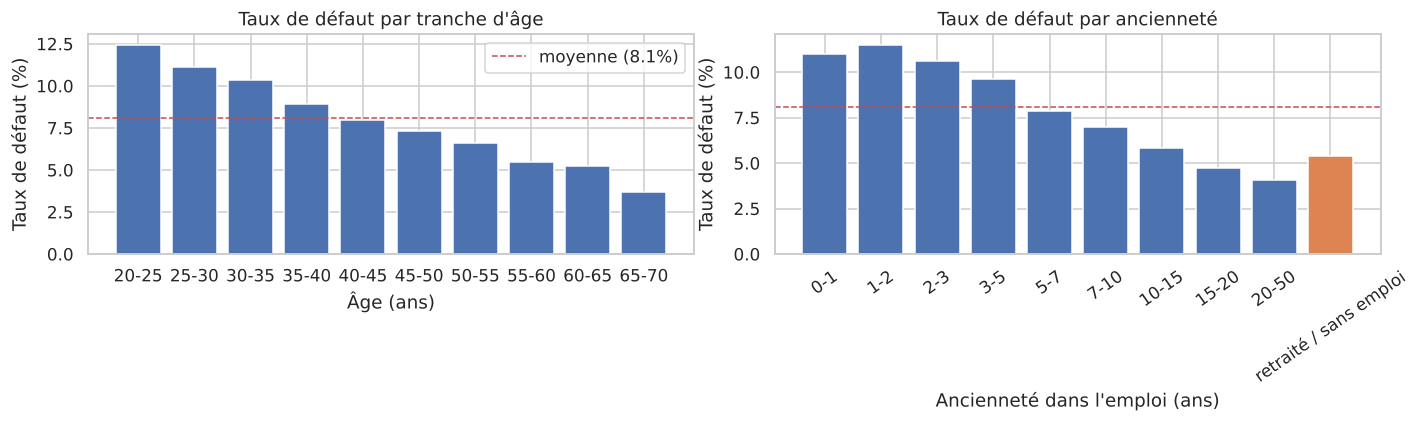

In [16]:
age = -df["DAYS_BIRTH"] / 365.25
anciennete = (-df["DAYS_EMPLOYED"].where(~anomalie_emploi)) / 365.25

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
par_age = df.groupby(pd.cut(age, bins=range(20, 75, 5)), observed=True)["TARGET"].agg(["mean", "size"])
axes[0].bar([f"{int(i.left)}-{int(i.right)}" for i in par_age.index], par_age["mean"] * 100, color="#4C72B0")
axes[0].axhline(taux_defaut * 100, color="#C44E52", ls="--", lw=1, label=f"moyenne ({taux_defaut:.1%})")
axes[0].set(xlabel="Âge (ans)", ylabel="Taux de défaut (%)", title="Taux de défaut par tranche d'âge")
axes[0].legend()

bornes = [0, 1, 2, 3, 5, 7, 10, 15, 20, 50]
par_anc = df.groupby(pd.cut(anciennete, bins=bornes), observed=True)["TARGET"].agg(["mean", "size"])
etiquettes = [f"{i.left}-{i.right}" for i in par_anc.index] + ["retraité / sans emploi"]
valeurs = list(par_anc["mean"] * 100) + [df.loc[anomalie_emploi, "TARGET"].mean() * 100]
axes[1].bar(etiquettes, valeurs, color=["#4C72B0"] * len(par_anc) + ["#DD8452"])
axes[1].axhline(taux_defaut * 100, color="#C44E52", ls="--", lw=1)
axes[1].set(xlabel="Ancienneté dans l'emploi (ans)", ylabel="Taux de défaut (%)", title="Taux de défaut par ancienneté")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

**Lecture.** Les deux relations sont nettes et **monotones** :
- le taux de défaut baisse régulièrement avec l'âge, de 12,4 % chez les 20-25 ans à 3,7 % chez les 65-70 ans ;
- il baisse aussi avec l'ancienneté dans l'emploi, d'environ 11 % la première année à 4 % au-delà de 20 ans. Les retraités (en orange) se situent à 5,4 %, nettement sous la moyenne.

La stabilité de la situation est l'un des signaux de risque les plus classiques en crédit, et ces données le confirment.

## 7.2 Les scores externes

`EXT_SOURCE_1`, `_2` et `_3` sont des scores normalisés entre 0 et 1, fournis par des sources externes (le dictionnaire n'en dit pas plus ; ce sont vraisemblablement des scores de bureaux de crédit).

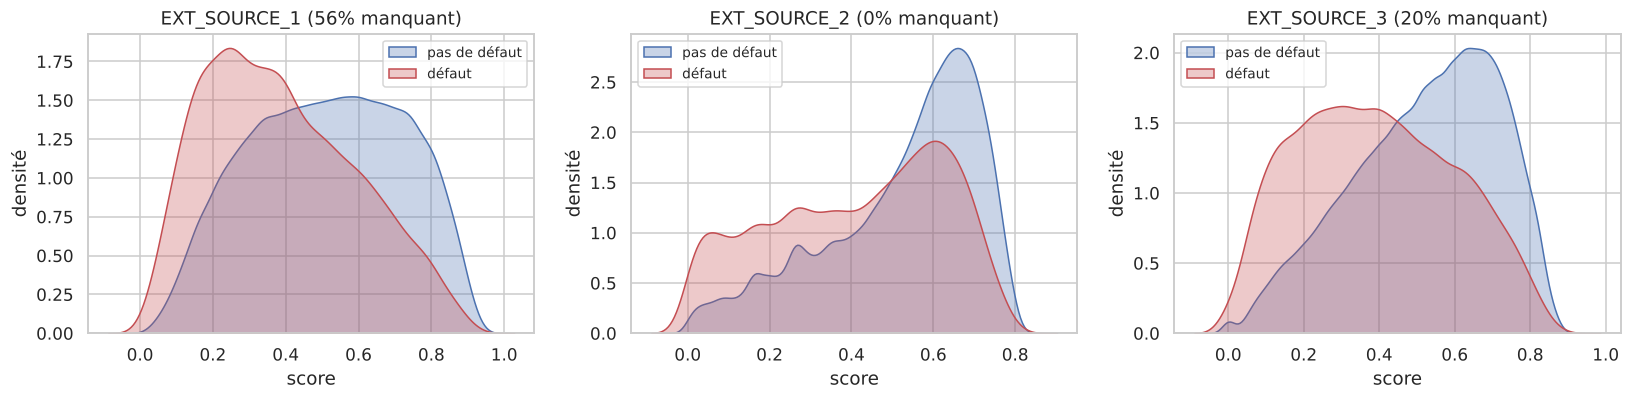

Corrélations entre les trois scores et avec la cible :
              EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3  TARGET
EXT_SOURCE_1         1.000         0.214         0.189  -0.155
EXT_SOURCE_2         0.214         1.000         0.110  -0.160
EXT_SOURCE_3         0.189         0.110         1.000  -0.179
TARGET              -0.155        -0.160        -0.179   1.000


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, v in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    for cible, couleur, nom in [(0, "#4C72B0", "pas de défaut"), (1, "#C44E52", "défaut")]:
        sns.kdeplot(df.loc[df["TARGET"] == cible, v].dropna(), ax=ax, color=couleur, fill=True, alpha=0.3,
                    label=nom, common_norm=False)
    ax.set(title=f"{v} ({df[v].isna().mean():.0%} manquant)", xlabel="score", ylabel="densité")
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("Corrélations entre les trois scores et avec la cible :")
print(df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "TARGET"]].corr().round(3))

**Lecture.** Les trois scores externes séparent nettement les deux populations : les clients en défaut ont des scores beaucoup plus bas. Ce sont les variables les plus corrélées à la cible (−0,16 à −0,18). Leurs corrélations mutuelles restent faibles (0,11 à 0,21) : **ils portent des informations en partie différentes**, et il sera utile de les combiner.

Point d'attention : `EXT_SOURCE_1` manque dans 56 % des cas et `EXT_SOURCE_3` dans 20 %. Leur traitement (indicatrice + imputation) comptera beaucoup dans la performance finale.

## 7.3 Variables qualitatives

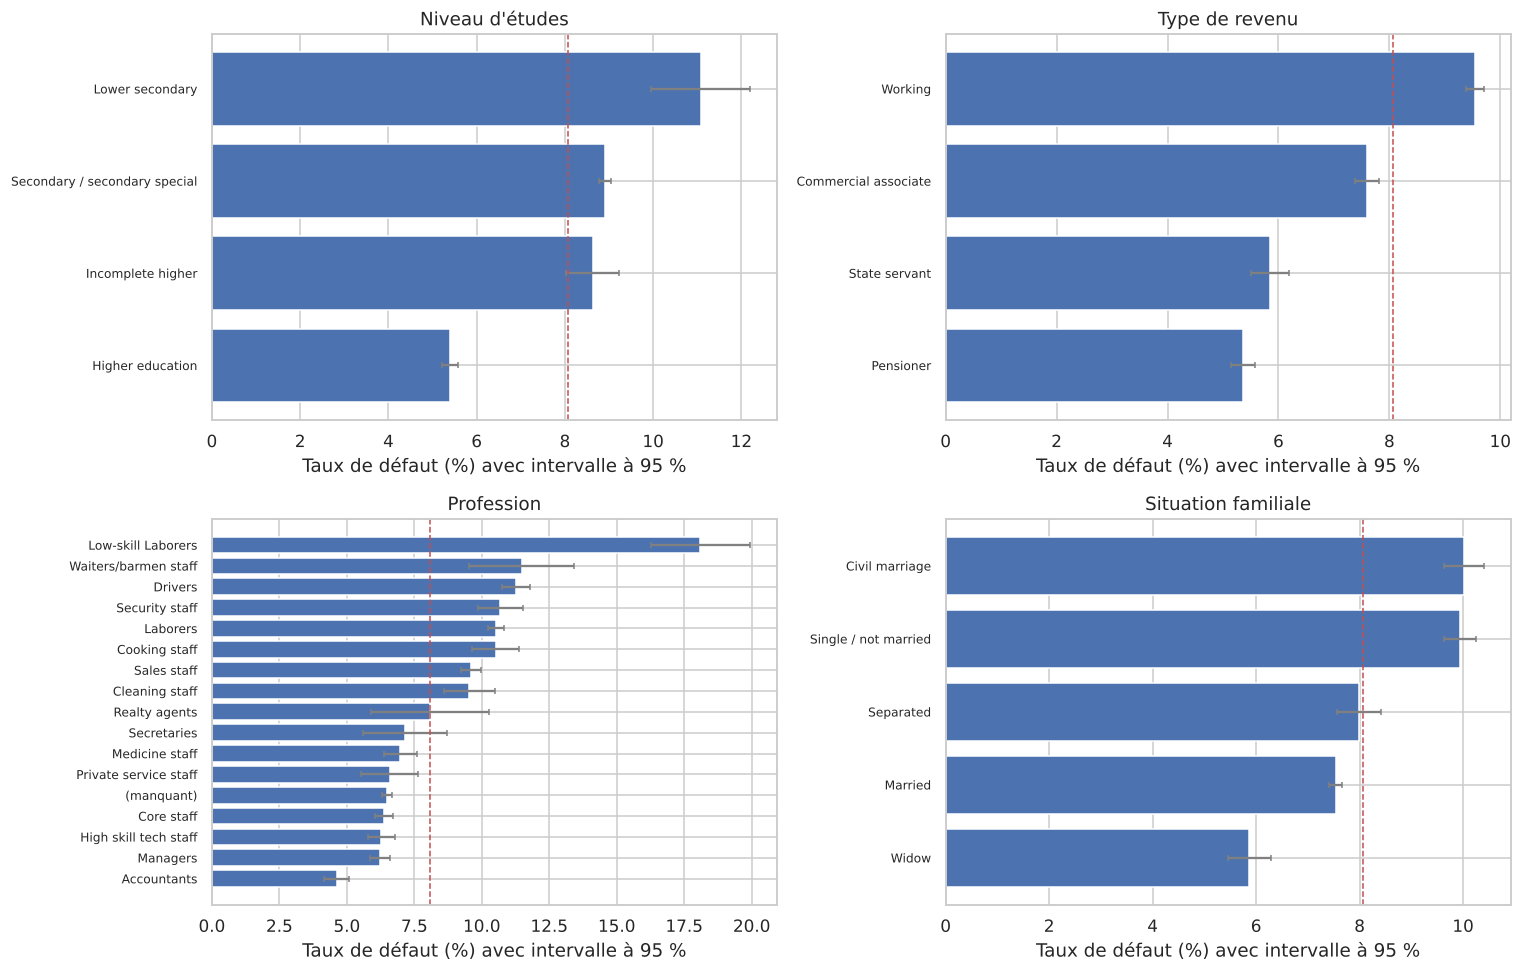

In [18]:
def taux_par_modalite(v, min_effectif=500):
    t = df.groupby(df[v].fillna("(manquant)"))["TARGET"].agg(taux="mean", effectif="size")
    t = t[t["effectif"] >= min_effectif].sort_values("taux")
    erreur = 1.96 * np.sqrt(t["taux"] * (1 - t["taux"]) / t["effectif"])
    return t.assign(erreur=erreur)


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, v, titre in zip(axes.ravel(),
                        ["NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "OCCUPATION_TYPE", "NAME_FAMILY_STATUS"],
                        ["Niveau d'études", "Type de revenu", "Profession", "Situation familiale"]):
    t = taux_par_modalite(v)
    ax.barh(t.index, t["taux"] * 100, xerr=t["erreur"] * 100, color="#4C72B0", ecolor="grey", capsize=2)
    ax.axvline(taux_defaut * 100, color="#C44E52", ls="--", lw=1)
    ax.set(title=titre, xlabel="Taux de défaut (%) avec intervalle à 95 %")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Lecture.**
- **Niveau d'études :** l'écart est fort, de 5,4 % de défaut pour les diplômés du supérieur à 11 % pour le premier cycle du secondaire.
- **Type de revenu :** les salariés du privé (`Working`, 9,6 %) sont plus risqués que les fonctionnaires (5,8 %) et les retraités (5,4 %), dont les revenus sont plus stables.
- **Profession :** l'éventail est le plus large, de 4,6 % (comptables) à environ 18 % (ouvriers peu qualifiés). Les intervalles de confiance montrent que les écarts sont significatifs pour les modalités les plus fréquentes.
- **Situation familiale :** les célibataires et les couples en union libre (environ 10 %) sont plus risqués que les mariés (7,5 %) et les veufs (5,9 %). Cette dernière différence reflète en partie l'âge.

# 8. Pouvoir discriminant de chaque variable

Deux mesures complémentaires, classiques en scoring de crédit :

**AUC univariée.** On utilise une variable seule comme score et on calcule son AUC. Une AUC de 0,5 signifie aucun pouvoir de séparation ; on retient $\max(AUC, 1 - AUC)$ pour ne pas dépendre du sens de la relation.

**Information Value (IV).** On découpe la variable en classes (déciles pour une variable continue, modalités pour une variable qualitative, avec une classe à part pour les valeurs manquantes). Pour chaque classe $i$, le *Weight of Evidence* compare la part des bons et des mauvais payeurs :

$$WoE_i = \ln\left(\frac{\%\,\text{bons}_i}{\%\,\text{mauvais}_i}\right), \qquad IV = \sum_i \left(\%\,\text{bons}_i - \%\,\text{mauvais}_i\right) \times WoE_i$$

Grille de lecture usuelle : IV < 0,02 inutile ; 0,02 à 0,1 faible ; 0,1 à 0,3 moyen ; > 0,3 fort. L'IV a l'avantage de traiter variables qualitatives, continues et valeurs manquantes de la même façon.

In [19]:
def classes(serie, nb_classes=10):
    if serie.dtype.kind in "biuf" and serie.nunique() > nb_classes:
        c = pd.qcut(serie, nb_classes, duplicates="drop").astype(str)
    else:
        c = serie.astype(str)
        frequences = c.value_counts(normalize=True)
        c = c.where(c.map(frequences) >= 0.01, "autres")
    return c.where(serie.notna(), "manquant")


def information_value(serie, cible):
    t = pd.crosstab(classes(serie), cible) + 0.5
    bons, mauvais = t[0] / t[0].sum(), t[1] / t[1].sum()
    woe = np.log(bons / mauvais)
    return float(((bons - mauvais) * woe).sum())


def auc_univariee(serie, cible):
    if serie.dtype.kind not in "biuf":
        return np.nan
    masque = serie.notna()
    if serie[masque].nunique() < 2:
        return np.nan
    auc = roc_auc_score(cible[masque], serie[masque])
    return max(auc, 1 - auc)


explicatives = [c for c in df.columns if c not in ("SK_ID_CURR", "TARGET")]
df_iv = df.copy()
df_iv["DAYS_EMPLOYED"] = df_iv["DAYS_EMPLOYED"].where(~anomalie_emploi)
pouvoir = pd.DataFrame({
    "famille": familles[explicatives],
    "IV": [information_value(df_iv[v], df_iv["TARGET"]) for v in explicatives],
    "AUC univariée": [auc_univariee(df_iv[v], df_iv["TARGET"]) for v in explicatives],
    "% manquant": df_iv[explicatives].isna().mean() * 100,
}).sort_values("IV", ascending=False)
pouvoir["force"] = pd.cut(pouvoir["IV"], [-np.inf, 0.02, 0.1, 0.3, np.inf], labels=["inutile", "faible", "moyen", "fort"])
print(pouvoir["force"].value_counts().sort_index())
pouvoir.head(20).round(3)

force
inutile    67
faible     49
moyen       2
fort        2
Name: count, dtype: int64


,famille,IV,AUC univariée,% manquant,force
EXT_SOURCE_3,Scores externes,0.330,0.680,19.839,fort
EXT_SOURCE_2,Scores externes,0.303,0.655,0.216,fort
EXT_SOURCE_1,Scores externes,0.151,0.666,56.338,moyen
DAYS_EMPLOYED,Revenus et emploi,0.112,0.582,17.944,moyen
AMT_GOODS_PRICE,Crédit demandé,0.091,0.534,0.090,faible
DAYS_BIRTH,Profil sociodémographique,0.087,0.584,0.000,faible
OCCUPATION_TYPE,Revenus et emploi,0.082,NaN,31.275,faible
ORGANIZATION_TYPE,Revenus et emploi,0.060,NaN,0.000,faible
NAME_INCOME_TYPE,Revenus et emploi,0.056,NaN,0.000,faible
REGION_RATING_CLIENT_W_CITY,Région et adresse,0.052,0.549,0.000,faible


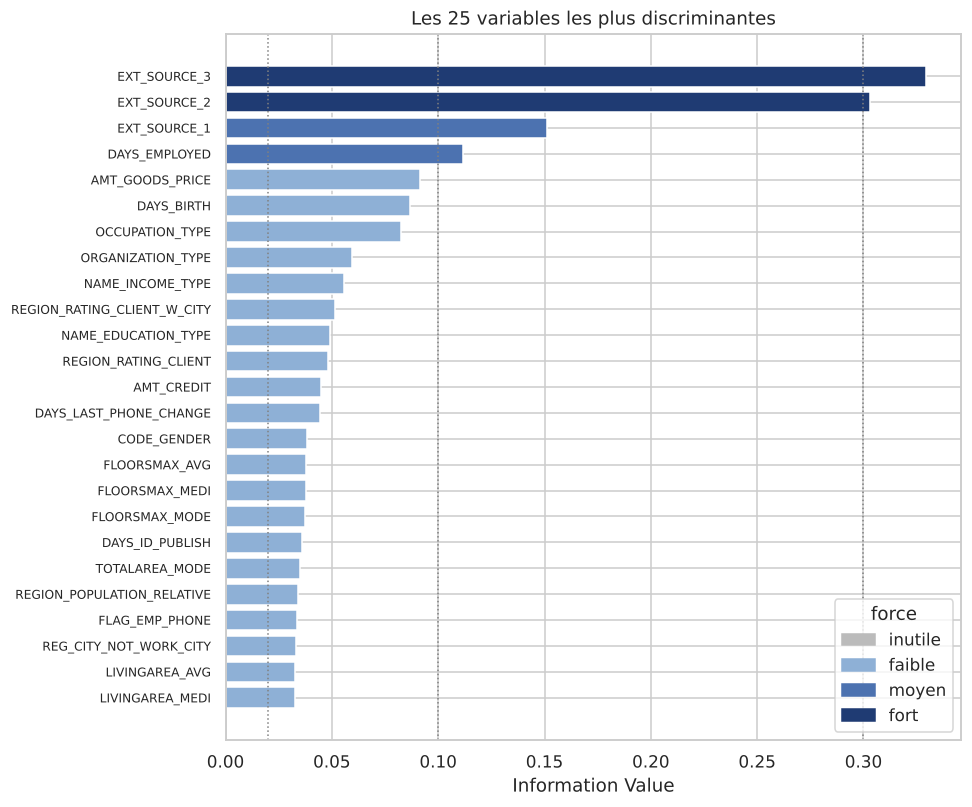

In [20]:
top = pouvoir.head(25).iloc[::-1]
couleurs_force = {"inutile": "#BBBBBB", "faible": "#8EB0D6", "moyen": "#4C72B0", "fort": "#1F3B73"}
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(top.index, top["IV"], color=[couleurs_force[f] for f in top["force"]])
for seuil in (0.02, 0.1, 0.3):
    ax.axvline(seuil, color="grey", ls=":", lw=1)
ax.set(xlabel="Information Value", title="Les 25 variables les plus discriminantes")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in couleurs_force.values()],
          labels=list(couleurs_force.keys()), title="force", loc="lower right")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [21]:
print("Variables jugées inutiles (IV < 0,02) :", (pouvoir["force"] == "inutile").sum())
print(pouvoir[pouvoir["force"] == "inutile"].groupby("famille").size().sort_values(ascending=False))

Variables jugées inutiles (IV < 0,02) : 67
famille
Caractéristiques de l'immeuble       19
Documents fournis                    19
Consultations du bureau de crédit     6
Coordonnées fournies                  5
Crédit demandé                        4
Défauts dans l'entourage              4
Région et adresse                     4
Patrimoine et logement                3
Profil sociodémographique             2
Revenus et emploi                     1
dtype: int64


**Lecture.**
- **Seules 4 variables sur 120 ont une IV moyenne ou forte** : les trois scores externes (`EXT_SOURCE_3` 0,33, `EXT_SOURCE_2` 0,30, `EXT_SOURCE_1` 0,15) et l'ancienneté dans l'emploi (0,11).
- Viennent ensuite des variables faibles mais utiles : prix du bien, âge, profession, type d'employeur, type de revenu, note de la région, niveau d'études.
- **67 variables ont une IV inférieure à 0,02**, dont 19 documents fournis sur 20 et 19 variables d'immeuble. Elles n'apportent presque rien prises une à une.

Deux nuances : l'IV mesure un pouvoir **univarié**, et une variable faible seule peut devenir utile en combinaison. Et l'AUC univariée n'existe pas pour les variables qualitatives, d'où l'intérêt de l'IV pour comparer toutes les variables sur la même échelle.

**Décision :** on ne supprime rien à ce stade, mais les familles « documents » et « immeuble » seront réduites (section 9) et la sélection finale se fera en mesurant l'apport réel au modèle.

# 9. Redondances

## 9.1 Les caractéristiques de l'immeuble

Les 47 variables sur l'immeuble existent en trois versions : moyenne (`_AVG`), mode (`_MODE`) et médiane (`_MEDI`).

In [22]:
immeuble = [c for c in df.columns if familles[c] == "Caractéristiques de l'immeuble" and df[c].dtype.kind == "f"]
racines = sorted({c.rsplit("_", 1)[0] for c in immeuble if c.endswith("_AVG")})
correlations_versions = pd.DataFrame({
    "AVG / MEDI": [df[f"{r}_AVG"].corr(df[f"{r}_MEDI"]) for r in racines],
    "AVG / MODE": [df[f"{r}_AVG"].corr(df[f"{r}_MODE"]) for r in racines],
}, index=racines).round(3)
correlations_versions

,AVG / MEDI,AVG / MODE
APARTMENTS,0.995,0.974
BASEMENTAREA,0.994,0.973
COMMONAREA,0.996,0.976
ELEVATORS,0.996,0.979
ENTRANCES,0.997,0.978
FLOORSMAX,0.997,0.986
FLOORSMIN,0.997,0.986
LANDAREA,0.991,0.973
LIVINGAPARTMENTS,0.994,0.969
LIVINGAREA,0.995,0.972


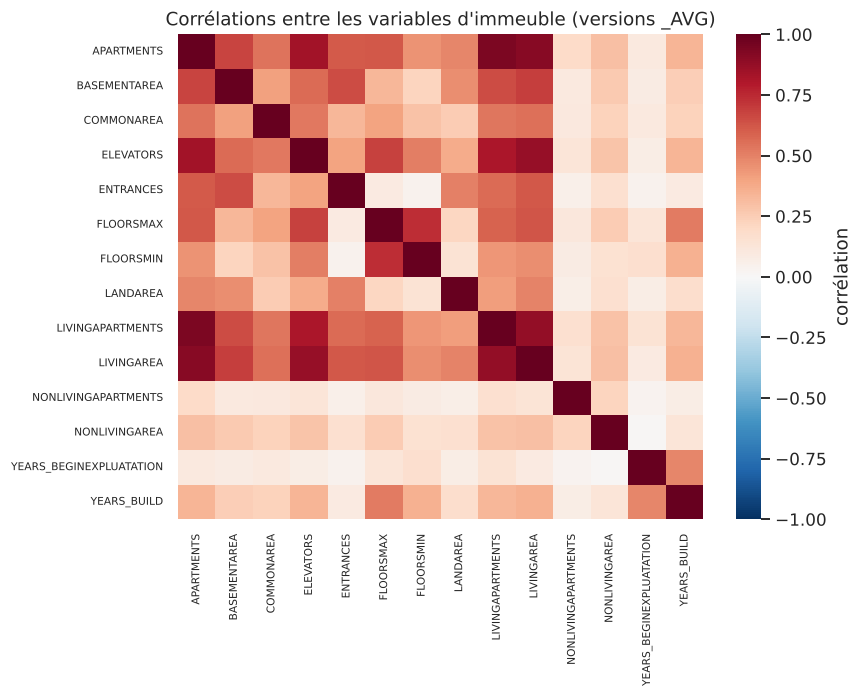

In [23]:
fig, ax = plt.subplots(figsize=(8, 6.5))
avg = [f"{r}_AVG" for r in racines]
sns.heatmap(df[avg].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            xticklabels=racines, yticklabels=racines, cbar_kws={"label": "corrélation"})
ax.set_title("Corrélations entre les variables d'immeuble (versions _AVG)")
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()

**Lecture.** Les versions moyenne, médiane et mode d'une même caractéristique sont corrélées à plus de 0,97 : **elles contiennent la même information en triple**. La carte de chaleur montre en plus deux blocs de variables très liées entre elles (surfaces et nombres d'appartements d'un côté, nombre d'étages de l'autre).

**Décision :** ne garder que les versions `_AVG`, plus `TOTALAREA_MODE`, ainsi qu'une indicatrice « informations sur l'immeuble manquantes », dont on a vu qu'elle était porteuse de risque. On passe ainsi de 47 à une quinzaine de variables sans perte d'information.

## 9.2 Montants du crédit

In [24]:
print(df[["AMT_CREDIT", "AMT_GOODS_PRICE", "AMT_ANNUITY", "AMT_INCOME_TOTAL"]].corr().round(3))
print("\nAutres paires très corrélées (|r| > 0,9), hors immeuble :")
numeriques = [c for c in explicatives if df[c].dtype.kind in "if" and familles[c] != "Caractéristiques de l'immeuble"]
matrice = df[numeriques].corr().abs()
paires = (matrice.where(np.triu(np.ones(matrice.shape, dtype=bool), k=1)).stack()
          .loc[lambda s: s > 0.9].sort_values(ascending=False))
print(paires.round(3).to_string())

                  AMT_CREDIT  AMT_GOODS_PRICE  AMT_ANNUITY  AMT_INCOME_TOTAL
AMT_CREDIT             1.000            0.987        0.770             0.144
AMT_GOODS_PRICE        0.987            1.000        0.775             0.146
AMT_ANNUITY            0.770            0.775        1.000             0.175
AMT_INCOME_TOTAL       0.144            0.146        0.175             1.000

Autres paires très corrélées (|r| > 0,9), hors immeuble :


DAYS_EMPLOYED             FLAG_EMP_PHONE                 1.000
OBS_30_CNT_SOCIAL_CIRCLE  OBS_60_CNT_SOCIAL_CIRCLE       0.999
AMT_CREDIT                AMT_GOODS_PRICE                0.987
REGION_RATING_CLIENT      REGION_RATING_CLIENT_W_CITY    0.951


**Lecture.**
- **Le montant du crédit et le prix du bien sont corrélés à 0,99** : le prêt finance presque toujours le prix du bien. C'est leur **rapport** qui est informatif (section 10), pas leur niveau.
- **`DAYS_EMPLOYED` et `FLAG_EMP_PHONE`** semblent parfaitement corrélés (1,000). C'est un artefact du code 365 243 : les retraités n'ont ni ancienneté ni téléphone professionnel. Cet effet disparaîtra une fois le code remplacé.
- `OBS_30_CNT_SOCIAL_CIRCLE` et `OBS_60_CNT_SOCIAL_CIRCLE` sont quasiment identiques (0,999), tout comme les deux notes de région (0,95) : on ne gardera qu'une variable de chaque paire.

# 10. Variables dérivées

Un analyste crédit ne regarde pas le montant emprunté seul, mais **rapporté aux capacités du client**. On construit quelques ratios classiques et on mesure leur pouvoir discriminant.

| Variable dérivée | Définition | Interprétation |
|---|---|---|
| `TAUX_EFFORT` | annuité / revenu | part du revenu consacrée au remboursement |
| `CREDIT_REVENU` | crédit / revenu | endettement en années de revenu |
| `DUREE_ANNUITES` | crédit / annuité | durée approximative du prêt, en nombre d'échéances |
| `PART_FINANCEE` | crédit / prix du bien | > 1 si le prêt finance plus que le bien (assurance, frais) |
| `AGE` | −DAYS_BIRTH / 365,25 | âge en années |
| `ANCIENNETE_SUR_AGE` | ancienneté d'emploi / âge | stabilité professionnelle relative |
| `MOYENNE_EXT` | moyenne des scores externes renseignés | synthèse des trois scores |

In [25]:
derivees = pd.DataFrame(index=df.index)
derivees["TAUX_EFFORT"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
derivees["CREDIT_REVENU"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
derivees["DUREE_ANNUITES"] = df["AMT_CREDIT"] / df["AMT_ANNUITY"]
derivees["PART_FINANCEE"] = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"]
derivees["AGE"] = age
derivees["ANCIENNETE_SUR_AGE"] = anciennete / age
derivees["MOYENNE_EXT"] = df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)

comparaison = pd.DataFrame({
    "IV": [information_value(derivees[v], df["TARGET"]) for v in derivees],
    "AUC univariée": [auc_univariee(derivees[v], df["TARGET"]) for v in derivees],
}, index=derivees.columns)
reference = pouvoir.loc[["AMT_ANNUITY", "AMT_CREDIT", "AMT_INCOME_TOTAL", "AMT_GOODS_PRICE", "DAYS_BIRTH",
                         "DAYS_EMPLOYED", "EXT_SOURCE_3"], ["IV", "AUC univariée"]]
pd.concat({"variables dérivées": comparaison, "variables d'origine (rappel)": reference}).round(3)

IV  AUC univariée
variables dérivées           TAUX_EFFORT         0.006          0.521
                             CREDIT_REVENU       0.011          0.502
                             DUREE_ANNUITES      0.142          0.533
                             PART_FINANCEE       0.072          0.568
                             AGE                 0.087          0.584
                             ANCIENNETE_SUR_AGE  0.091          0.569
                             MOYENNE_EXT         0.609          0.717
variables d'origine (rappel) AMT_ANNUITY         0.025          0.500
                             AMT_CREDIT          0.045          0.519
                             AMT_INCOME_TOTAL    0.011          0.520
                             AMT_GOODS_PRICE     0.091          0.534
                             DAYS_BIRTH          0.087          0.584
                             DAYS_EMPLOYED       0.112          0.582
                             EXT_SOURCE_3        0.330          0.680

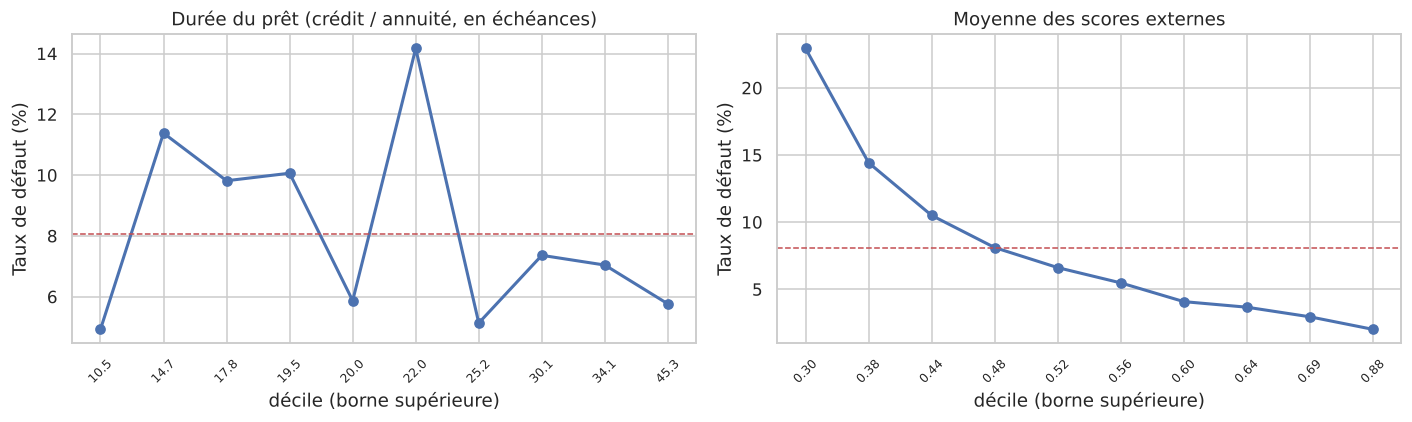

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, v, titre in [(axes[0], "DUREE_ANNUITES", "Durée du prêt (crédit / annuité, en échéances)"),
                     (axes[1], "MOYENNE_EXT", "Moyenne des scores externes")]:
    t = df.groupby(pd.qcut(derivees[v], 10, duplicates="drop"), observed=True)["TARGET"].mean() * 100
    ax.plot(range(len(t)), t.values, marker="o", color="#4C72B0", lw=2)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([f"{i.right:.2f}" if v == "MOYENNE_EXT" else f"{i.right:.1f}" for i in t.index], rotation=45, fontsize=8)
    ax.axhline(taux_defaut * 100, color="#C44E52", ls="--", lw=1)
    ax.set(title=titre, xlabel="décile (borne supérieure)", ylabel="Taux de défaut (%)")
plt.tight_layout()
plt.show()

**Lecture.**
- **La moyenne des scores externes** est de loin la meilleure variable de toute l'étude : IV de 0,61 et AUC de 0,72, contre 0,33 et 0,68 pour le meilleur score pris seul. Le taux de défaut passe de 23 % dans le premier décile à 2 % dans le dernier.
- **La durée du prêt** a une IV élevée (0,14) mais une AUC presque nulle (0,53). Le graphique explique ce paradoxe : la relation n'est pas monotone. Le rapport crédit / annuité se concentre sur quelques valeurs précises (20, 34, 21, 10…), qui correspondent vraisemblablement à des grilles de produits commerciaux, chacun avec son propre niveau de risque. Une régression logistique ne saura pas exploiter cette forme en dents de scie sans découpage en classes ; un modèle à base d'arbres le fera naturellement.
- **La part financée** (0,07) et **l'ancienneté rapportée à l'âge** (0,09) apportent un signal comparable à leurs variables d'origine.
- **Le taux d'effort et l'endettement rapporté au revenu**, pourtant centraux pour un banquier, sont presque inutiles ici (IV < 0,02). Le revenu déclaré, non vérifié et parfois aberrant, est sans doute trop bruité pour que ces ratios soient fiables.

# 11. Équité : les variables sensibles

Un modèle de crédit ne doit pas discriminer selon des caractéristiques protégées. En France comme dans l'Union européenne, le **sexe** ne peut pas être utilisé pour fixer les conditions d'un crédit ; la situation familiale relève de la même logique. L'âge est un cas particulier : il est couramment utilisé en scoring, mais son usage doit être justifié et proportionné.

In [27]:
for v in ["CODE_GENDER", "NAME_FAMILY_STATUS"]:
    t = df[~df[v].isin(["XNA", "Unknown"])].groupby(v)["TARGET"].agg(taux_defaut="mean", effectif="size")
    print(f"\n{v}")
    print(t.assign(taux_defaut=lambda d: (d["taux_defaut"] * 100).round(2)))
print(f"\nIV de CODE_GENDER : {pouvoir.loc['CODE_GENDER', 'IV']:.3f}")


CODE_GENDER
             taux_defaut  effectif
CODE_GENDER                       
F                   7.00    161887
M                  10.14     84119

NAME_FAMILY_STATUS
                      taux_defaut  effectif
NAME_FAMILY_STATUS                         
Civil marriage              10.02     23812
Married                      7.53    157153
Separated                    7.99     15840
Single / not married         9.95     36359
Widow                        5.87     12842

IV de CODE_GENDER : 0.038


**Lecture.** Les hommes ont un taux de défaut nettement plus élevé que les femmes (10,1 % contre 7,0 %) : la variable est discriminante au sens statistique (IV de 0,04). Elle est pourtant **exclue du modèle**, pour des raisons réglementaires (interdiction de discriminer selon le sexe dans l'accès au crédit) et éthiques.

L'exclure ne suffit pas : d'autres variables peuvent servir de **variables de substitution** (profession, type de revenu…). Le notebook de modélisation comportera donc un **contrôle d'équité** : on y comparera le taux d'acceptation et le taux d'erreur du modèle final entre hommes et femmes, en gardant `CODE_GENDER` à part uniquement pour cet audit. La situation familiale suivra le même traitement.

# 12. Synthèse et règles pour le nettoyage

## Ce que l'on retient

1. **La cible est déséquilibrée** (8,1 % de défauts) : on utilisera l'AUC, le Gini, l'AUC précision-rappel et le score de Brier, avec une validation croisée stratifiée et un seuil fixé selon les coûts.
2. **Le signal est concentré** dans les scores externes, l'âge, l'ancienneté, la profession, le niveau d'études et la région. La moyenne des trois scores externes est la meilleure variable de la base.
3. **Les valeurs manquantes sont informatives** et ne seront jamais supprimées ligne à ligne.
4. **Une grande partie des colonnes est redondante ou peu utile** : versions multiples des variables d'immeuble, documents fournis.

## Règles pour le notebook 02 (nettoyage et préparation)

| Problème | Traitement | Appris sur |
|---|---|---|
| `DAYS_EMPLOYED = 365243` | valeur manquante + indicatrice `SANS_EMPLOI` | règle fixe |
| `XNA` / `Unknown` | valeurs manquantes | règle fixe |
| Durées en jours négatifs | conversion en années positives | règle fixe |
| Revenus aberrants | écrêtage au 99,9ᵉ centile | apprentissage |
| `OWN_CAR_AGE`, `OCCUPATION_TYPE` des retraités | modalité « sans objet » | règle fixe |
| Variables d'immeuble | garder `_AVG` + `TOTALAREA_MODE` + indicatrice de manque | règle fixe |
| Paires quasi identiques | garder une variable par paire | règle fixe |
| Valeurs manquantes restantes | indicatrice + médiane ou modalité la plus fréquente | apprentissage (pipeline) |
| Variables qualitatives | encodage one-hot (modalités rares regroupées) ou WoE | apprentissage |
| Variables dérivées | moyenne des scores externes, part financée, durée, ancienneté / âge, âge | règle fixe |
| `CODE_GENDER`, `NAME_FAMILY_STATUS` | exclues du modèle, conservées pour l'audit d'équité | — |

Les règles fixes peuvent s'appliquer à toute la base sans risque de fuite. Celles qui dépendent des données (centiles, médianes, modalités fréquentes, WoE) seront **apprises sur l'échantillon d'apprentissage uniquement**, dans un pipeline.

Le découpage apprentissage / test est enregistré dans `data/traitees/decoupage.csv` : tous les notebooks suivants l'utiliseront.